# Üç Öğretim Yönteminin Etkililiğinin Karşılaştırılması

**Amaç:** A, B ve C yöntemlerinin uygulandığı üç grupta ön test ve son test puanlarını karşılaştırarak

1. Gruplar arasında son test puanları bakımından anlamlı fark olup olmadığını,
2. En etkili yöntemin hangisi olduğunu,
3. En etkili yöntemin uygulandığı grupta ön test ile son test arasında anlamlı fark olup olmadığını

incelemek.

**Analiz akışı:** Veri üretme → ön test denkliği → varsayım kontrolleri → ANOVA / Kruskal-Wallis → post-hoc → en etkili grup → bağımlı t-testi / Wilcoxon → raporlama.

Her adımda uygun test, varsayım sonuçlarına göre **otomatik** seçilir; anlamlılık düzeyi α = 0.05.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import (f_oneway, kruskal, levene, mannwhitneyu, rankdata,
                         shapiro, ttest_ind, ttest_rel, tukey_hsd, wilcoxon)

ALPHA = 0.05
GRUPLAR = ["A", "B", "C"]
RENKLER = {"A": "#4C72B0", "B": "#DD8452", "C": "#55A868"}

pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})


def p_yaz(p):
    # APA biçiminde p değeri
    return "p < .001" if p < 0.001 else f"p = {p:.3f}".replace("0.", ".", 1)


def evet_hayir(kosul):
    return "Evet" if kosul else "Hayır"


def holm(p_degerleri):
    # Holm-Bonferroni düzeltmesi (çoklu karşılaştırma)
    p = np.asarray(p_degerleri, dtype=float)
    m = len(p)
    sira = np.argsort(p)
    duzeltilmis = np.empty(m)
    enbuyuk = 0.0
    for k, i in enumerate(sira):
        enbuyuk = max(enbuyuk, (m - k) * p[i])
        duzeltilmis[i] = min(enbuyuk, 1.0)
    return duzeltilmis


def eta_kare(*gruplar):
    # Tek yönlü ANOVA etki büyüklüğü: SS_gruplar_arası / SS_toplam
    tum = np.concatenate(gruplar)
    ss_arasi = sum(len(g) * (np.mean(g) - tum.mean()) ** 2 for g in gruplar)
    ss_toplam = ((tum - tum.mean()) ** 2).sum()
    return ss_arasi / ss_toplam


def etki_yorumu(deger, esikler):
    # esikler: (küçük, orta, büyük) alt sınırları
    if deger >= esikler[2]:
        return "büyük"
    if deger >= esikler[1]:
        return "orta"
    if deger >= esikler[0]:
        return "küçük"
    return "önemsiz"

# Veri Üretme (Gruplar için ön test ve son test verileri oluşturun):

**Genel Veri Seti:** Dataframe'deki değişken başlıkları: 'A_ön','A_son','B_ön','B_son','C_ön','C_son' olmalı.

**Hangi yöntemin etkili olduğunu incelemek için veri seti:** Son testleri karşılaştırmak için 'A_son','B_son','C_son' için ayrı bir dataframe daha oluşturun.

*Simülasyon tasarımı:* Her grupta n = 100 öğrenci vardır. Ön test puanları üç grupta da aynı dağılımdan gelir (N(55, 8)), yani gruplar başlangıçta denktir. Yöntemlerin beklenen etkisi A: +15, B: +5, C: +10 puandır. Puanlar 0–100 aralığına kırpılır. Sonuçların tekrarlanabilir olması için `seed = 42` sabitlenir.

In [2]:
np.random.seed(42)
n = 100

ON_ORT, ON_SS = 55, 8
ETKI = {"A": (15, 5), "B": (5, 4), "C": (10, 5)}   # (ortalama artış, standart sapma)

In [3]:
A_on = np.random.normal(loc=ON_ORT, scale=ON_SS, size=n)
B_on = np.random.normal(loc=ON_ORT, scale=ON_SS, size=n)
C_on = np.random.normal(loc=ON_ORT, scale=ON_SS, size=n)

In [4]:
A_son = A_on + np.random.normal(loc=ETKI["A"][0], scale=ETKI["A"][1], size=n)
B_son = B_on + np.random.normal(loc=ETKI["B"][0], scale=ETKI["B"][1], size=n)
C_son = C_on + np.random.normal(loc=ETKI["C"][0], scale=ETKI["C"][1], size=n)

In [5]:
# Genel veri seti
df = pd.DataFrame({
    "A_ön":  np.clip(A_on,  0, 100),
    "A_son": np.clip(A_son, 0, 100),
    "B_ön":  np.clip(B_on,  0, 100),
    "B_son": np.clip(B_son, 0, 100),
    "C_ön":  np.clip(C_on,  0, 100),
    "C_son": np.clip(C_son, 0, 100),
})

df.head()

,A_ön,A_son,B_ön,B_son,C_ön,C_son
0,58.974,69.829,43.677,42.299,57.862,72.493
1,53.894,66.093,51.635,54.237,59.486,79.033
2,60.182,78.918,52.258,57.279,63.664,66.672
3,67.184,85.236,48.582,53.770,63.430,76.245
4,53.127,68.022,53.710,56.909,43.979,50.725


In [6]:
# Hangi yöntemin etkili olduğunu incelemek için son test veri seti
df_son = df[["A_son", "B_son", "C_son"]].copy()

df_son.head()

,A_son,B_son,C_son
0,69.829,42.299,72.493
1,66.093,54.237,79.033
2,78.918,57.279,66.672
3,85.236,53.770,76.245
4,68.022,56.909,50.725


## Betimsel İstatistikler

In [7]:
betimsel = pd.DataFrame({
    "Ön ort.":  [df[f"{g}_ön"].mean() for g in GRUPLAR],
    "Ön ss":    [df[f"{g}_ön"].std() for g in GRUPLAR],
    "Son ort.": [df[f"{g}_son"].mean() for g in GRUPLAR],
    "Son ss":   [df[f"{g}_son"].std() for g in GRUPLAR],
    "Artış":    [(df[f"{g}_son"] - df[f"{g}_ön"]).mean() for g in GRUPLAR],
}, index=[f"Grup {g}" for g in GRUPLAR])

betimsel

,Ön ort.,Ön ss,Son ort.,Son ss,Artış
Grup A,54.169,7.265,69.703,7.835,15.534
Grup B,55.178,7.629,59.954,9.418,4.776
Grup C,55.519,8.674,64.943,9.186,9.423


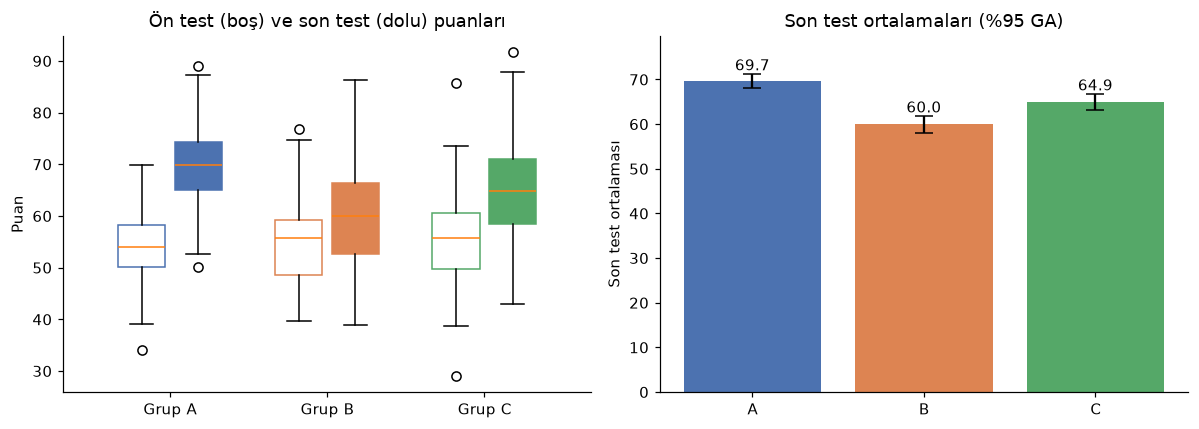

In [8]:
fig, eksenler = plt.subplots(1, 2, figsize=(11, 4))

konumlar = np.arange(len(GRUPLAR))
for kaydir, test, dolgu in [(-0.18, "ön", False), (0.18, "son", True)]:
    kutular = eksenler[0].boxplot([df[f"{g}_{test}"] for g in GRUPLAR], positions=konumlar + kaydir,
                                  widths=0.3, patch_artist=True)
    for kutu, g in zip(kutular["boxes"], GRUPLAR):
        kutu.set_facecolor(RENKLER[g] if dolgu else "white")
        kutu.set_edgecolor(RENKLER[g])
eksenler[0].set_xticks(konumlar, [f"Grup {g}" for g in GRUPLAR])
eksenler[0].set_ylabel("Puan")
eksenler[0].set_title("Ön test (boş) ve son test (dolu) puanları")

ortalamalar = df_son.mean()
hata = df_son.sem() * stats.t.ppf(0.975, n - 1)
eksenler[1].bar(GRUPLAR, ortalamalar, yerr=hata, capsize=6, color=[RENKLER[g] for g in GRUPLAR])
for i, (o, h) in enumerate(zip(ortalamalar, hata)):
    eksenler[1].text(i, o + h + 0.8, f"{o:.1f}", ha="center")
eksenler[1].set_ylim(0, ortalamalar.max() + 10)
eksenler[1].set_ylabel("Son test ortalaması")
eksenler[1].set_title("Son test ortalamaları (%95 GA)")

plt.tight_layout()
plt.show()

# Ön Test Denkliği

Son testleri karşılaştırarak yöntem etkisi hakkında yorum yapabilmek için grupların **başlangıçta denk** olması gerekir. Bu yüzden önce ön test puanları karşılaştırılır.

- H₀: Grupların ön test ortalamaları eşittir.
- H₁: En az bir grubun ön test ortalaması farklıdır.

Ön testler denk değilse son test karşılaştırması yanıltıcı olabilir; bu durumda kazanç (son − ön) puanları ya da ANCOVA tercih edilmelidir.

In [9]:
on_gruplari = [df[f"{g}_ön"] for g in GRUPLAR]
on_f, on_p = f_oneway(*on_gruplari)
on_denk = on_p > ALPHA

print(f"Ön test ANOVA: F(2, {3 * n - 3}) = {on_f:.2f}, {p_yaz(on_p)}")
print(f"Gruplar başlangıçta denk mi? {evet_hayir(on_denk)}")

Ön test ANOVA: F(2, 297) = 0.79, p = .453
Gruplar başlangıçta denk mi? Evet


# Normallik Varsayımı

Her grubun son test puanları için Shapiro-Wilk testi uygulanır.

- H₀: Veriler normal dağılımdan gelir.
- H₁: Veriler normal dağılımdan gelmez.

p > 0.05 ise normallik varsayımı sağlanır.

In [10]:
normallik = {}
for col in df_son.columns:
    w, p = shapiro(df_son[col])
    normallik[col] = p > ALPHA
    print(f"{col:6} | W = {w:.4f} | {p_yaz(p):10} | Normal mi? {evet_hayir(normallik[col])}")

normal_mi = all(normallik.values())
print(f"\nTüm gruplarda normallik sağlanıyor mu? {evet_hayir(normal_mi)}")

A_son  | W = 0.9961 | p = .994   | Normal mi? Evet
B_son  | W = 0.9883 | p = .530   | Normal mi? Evet
C_son  | W = 0.9938 | p = .932   | Normal mi? Evet

Tüm gruplarda normallik sağlanıyor mu? Evet


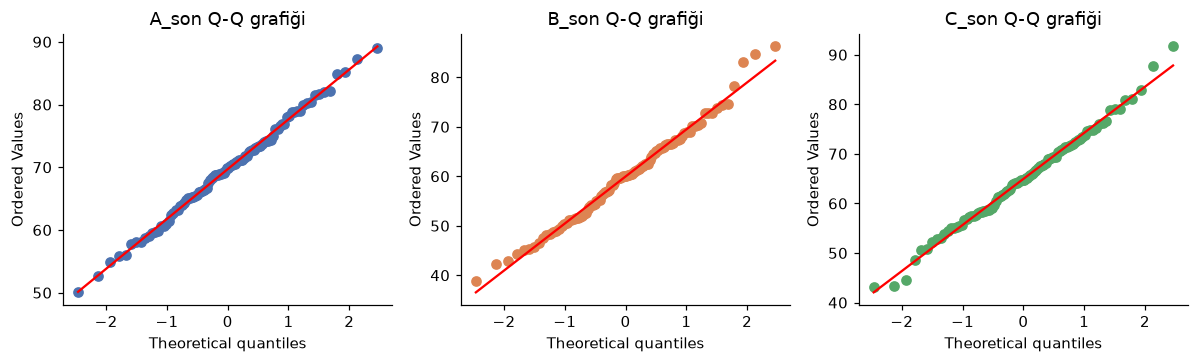

In [11]:
# Görsel kontrol: Q-Q grafikleri
fig, eksenler = plt.subplots(1, 3, figsize=(11, 3.4))
for eksen, g in zip(eksenler, GRUPLAR):
    stats.probplot(df_son[f"{g}_son"], dist="norm", plot=eksen)
    eksen.get_lines()[0].set_color(RENKLER[g])
    eksen.set_title(f"{g}_son Q-Q grafiği")
plt.tight_layout()
plt.show()

# Varyans Homojenliği Varsayımı

Levene testi (medyan merkezli, Brown-Forsythe) uygulanır.

- H₀: Grup varyansları eşittir.
- H₁: En az bir grubun varyansı farklıdır.

In [12]:
lev_stat, lev_p = levene(*[df_son[c] for c in df_son.columns])
homojen_mi = lev_p > ALPHA

print(f"Levene: W = {lev_stat:.4f}, {p_yaz(lev_p)} | Homojen mi? {evet_hayir(homojen_mi)}")

Levene: W = 1.5007, p = .225 | Homojen mi? Evet


### Test seçimi

| Normallik | Homojenlik | Kullanılacak test | Post-hoc |
|---|---|---|---|
| ✓ | ✓ | Tek yönlü ANOVA | Tukey HSD |
| ✓ | ✗ | Welch ANOVA | Welch t-testleri + Holm |
| ✗ | – | Kruskal-Wallis | Mann-Whitney U + Holm |

In [13]:
if normal_mi and homojen_mi:
    yontem = "anova"
elif normal_mi:
    yontem = "welch"
else:
    yontem = "kruskal"

YONTEM_ADI = {"anova": "Tek yönlü ANOVA", "welch": "Welch ANOVA", "kruskal": "Kruskal-Wallis H testi"}
print(f"Seçilen test: {YONTEM_ADI[yontem]}")

Seçilen test: Tek yönlü ANOVA


# Hipotez Testi
(Varyans Analizi): Varsayımlar sağlanıyorsa

- H₀: μ_A = μ_B = μ_C (yöntemlerin son test ortalamaları eşittir)
- H₁: En az bir yöntemin son test ortalaması farklıdır.

Etki büyüklüğü η² ile raporlanır (0.01 küçük, 0.06 orta, 0.14 büyük).

In [14]:
son_gruplari = [df_son[c] for c in df_son.columns]
N = sum(len(g) for g in son_gruplari)
sd_arasi, sd_ici = len(son_gruplari) - 1, N - len(son_gruplari)

if yontem == "welch":
    anova = f_oneway(*son_gruplari, equal_var=False)
else:
    anova = f_oneway(*son_gruplari)
eta2 = eta_kare(*son_gruplari)

print(f"{YONTEM_ADI['welch' if yontem == 'welch' else 'anova']}: "
      f"F({sd_arasi}, {sd_ici}) = {anova.statistic:.2f}, {p_yaz(anova.pvalue)}, "
      f"η² = {eta2:.3f} ({etki_yorumu(eta2, (0.01, 0.06, 0.14))} etki)")
if yontem == "kruskal":
    print("Not: Normallik sağlanmadığı için bu sonuç bilgi amaçlıdır; Kruskal-Wallis sonucu esas alınır.")

Tek yönlü ANOVA: F(2, 297) = 30.41, p < .001, η² = 0.170 (büyük etki)


# Hipotez Testi
(Kruskal-Wallis): Varsayımlar sağlanmıyorsa

- H₀: Grupların son test dağılımları (medyanları) aynıdır.
- H₁: En az bir grubun dağılımı farklıdır.

Etki büyüklüğü ε² = H / (N − 1) ile raporlanır (0.01 küçük, 0.08 orta, 0.26 büyük).

In [15]:
kw = kruskal(*son_gruplari)
eps2 = kw.statistic / (N - 1)

print(f"Kruskal-Wallis: H({sd_arasi}) = {kw.statistic:.2f}, {p_yaz(kw.pvalue)}, "
      f"ε² = {eps2:.3f} ({etki_yorumu(eps2, (0.01, 0.08, 0.26))} etki)")
if yontem != "kruskal":
    print("Not: Parametrik varsayımlar sağlandığı için bu sonuç bilgi amaçlıdır; ANOVA sonucu esas alınır.")

genel_p = kw.pvalue if yontem == "kruskal" else anova.pvalue
gruplar_farkli = genel_p < ALPHA
print(f"\nGruplar arasında anlamlı fark var mı? {evet_hayir(gruplar_farkli)}")

Kruskal-Wallis: H(2) = 52.50, p < .001, ε² = 0.176 (orta etki)
Not: Parametrik varsayımlar sağlandığı için bu sonuç bilgi amaçlıdır; ANOVA sonucu esas alınır.

Gruplar arasında anlamlı fark var mı? Evet


# Post-hoc Karşılaştırmalar

Genel test yalnızca "en az bir grup farklıdır" der; **hangi** grupların farklı olduğunu söylemez. En etkili yöntemi belirlemek için ikili karşılaştırmalar yapılır. Bir yöntem, diğer **her** yöntemden anlamlı olarak yüksekse "en etkili" kabul edilir.

In [16]:
ciftler = [(i, j) for i in range(len(GRUPLAR)) for j in range(i + 1, len(GRUPLAR))]
satirlar = []

if yontem == "anova":
    tukey = tukey_hsd(*son_gruplari)
    ga = tukey.confidence_interval(confidence_level=1 - ALPHA)
    for i, j in ciftler:
        satirlar.append({"Grup 1": GRUPLAR[i], "Grup 2": GRUPLAR[j],
                         "Ort. farkı": son_gruplari[i].mean() - son_gruplari[j].mean(),
                         "GA alt": ga.low[i, j], "GA üst": ga.high[i, j],
                         "p (düzeltilmiş)": tukey.pvalue[i, j]})
    posthoc_adi = "Tukey HSD"
else:
    ham_p = []
    for i, j in ciftler:
        if yontem == "welch":
            ham_p.append(ttest_ind(son_gruplari[i], son_gruplari[j], equal_var=False).pvalue)
        else:
            ham_p.append(mannwhitneyu(son_gruplari[i], son_gruplari[j]).pvalue)
    for (i, j), p in zip(ciftler, holm(ham_p)):
        satirlar.append({"Grup 1": GRUPLAR[i], "Grup 2": GRUPLAR[j],
                         "Ort. farkı": son_gruplari[i].mean() - son_gruplari[j].mean(),
                         "p (düzeltilmiş)": p})
    posthoc_adi = ("Welch t-testleri" if yontem == "welch" else "Mann-Whitney U") + " + Holm düzeltmesi"

posthoc = pd.DataFrame(satirlar)
posthoc["Anlamlı mı?"] = (posthoc["p (düzeltilmiş)"] < ALPHA).map(evet_hayir)
print(f"Post-hoc yöntemi: {posthoc_adi}")
posthoc

Post-hoc yöntemi: Tukey HSD


,Grup 1,Grup 2,Ort. farkı,GA alt,GA üst,p (düzeltilmiş),Anlamlı mı?
0,A,B,9.749,6.804,12.694,3.343e-13,Evet
1,A,C,4.761,1.816,7.706,4.987e-04,Evet
2,B,C,-4.988,-7.933,-2.043,2.454e-04,Evet


# En Etkili Yöntem

In [17]:
sirali = df_son.mean().sort_values(ascending=False)
aday = sirali.index[0][0]   # "A_son" -> "A"

aday_satirlari = posthoc[(posthoc["Grup 1"] == aday) | (posthoc["Grup 2"] == aday)]
aday_ustun = gruplar_farkli and (aday_satirlari["p (düzeltilmiş)"] < ALPHA).all()

print("Son test ortalamaları (büyükten küçüğe):")
for col, ort in sirali.items():
    print(f"  Grup {col[0]}: {ort:.2f}")

if aday_ustun:
    best_letter = aday
    print(f"\nEn etkili yöntem: Grup {best_letter} (diğer tüm gruplardan anlamlı olarak yüksek)")
else:
    best_letter = aday
    print(f"\nUyarı: Grup {aday} en yüksek ortalamaya sahip, ancak her gruptan anlamlı olarak yüksek değil."
          "\nTek bir 'en etkili yöntem' istatistiksel olarak belirlenemiyor; sonraki adımlar Grup "
          f"{aday} için yapılmıştır.")

Son test ortalamaları (büyükten küçüğe):
  Grup A: 69.70
  Grup C: 64.94
  Grup B: 59.95

En etkili yöntem: Grup A (diğer tüm gruplardan anlamlı olarak yüksek)


### Ek kontrol: Kazanç (son − ön) puanları

Kazanç puanları, öğrencilerin başlangıç düzeyindeki farklılıkları da hesaba katar. Bu analiz, son test sonucunun sağlamlığını kontrol etmek için yapılır.

In [18]:
df_gain = pd.DataFrame({f"{g}_gain": df[f"{g}_son"] - df[f"{g}_ön"] for g in GRUPLAR})

kazanc_f, kazanc_p = f_oneway(*[df_gain[c] for c in df_gain.columns])
kazanc_sirasi = df_gain.mean().sort_values(ascending=False)

print(f"Kazanç ANOVA: F(2, {3 * n - 3}) = {kazanc_f:.2f}, {p_yaz(kazanc_p)}")
print("Ortalama kazanç sırası:", " > ".join(f"{c[0]} ({v:.2f})" for c, v in kazanc_sirasi.items()))
print(f"Son test ile aynı grup mu en iyi? {evet_hayir(kazanc_sirasi.index[0][0] == best_letter)}")

Kazanç ANOVA: F(2, 297) = 148.11, p < .001
Ortalama kazanç sırası: A (15.53) > C (9.42) > B (4.78)
Son test ile aynı grup mu en iyi? Evet


# Veri setini Oluşturma:

**En etkili yöntemin bulunduğu grupta son test ve öntest arasındaki farklılığı incelemek için veri seti:** Ön ve son test verilerini alıp bir dataframe'e aktarın. (Bu veri seti varyans analizi sonucunda belirlenen en etkili yönteme ait ön ve son test verileri olmalıdır)

In [19]:
df_best = pd.DataFrame({
    "ön":  df[f"{best_letter}_ön"],
    "son": df[f"{best_letter}_son"],
})
fark = df_best["son"] - df_best["ön"]

print(f"En etkili grup: {best_letter}")
df_best.head()

En etkili grup: A


,ön,son
0,58.974,69.829
1,53.894,66.093
2,60.182,78.918
3,67.184,85.236
4,53.127,68.022


# Normallik Varsayımı

Bağımlı örneklem t-testinin varsayımı, **fark puanlarının** (son − ön) normal dağılmasıdır.

In [20]:
w, p = shapiro(fark)
fark_normal = p > ALPHA
print(f"Farkların Shapiro-Wilk testi: W = {w:.4f}, {p_yaz(p)} | Normal mi? {evet_hayir(fark_normal)}")

Farkların Shapiro-Wilk testi: W = 0.9899, p = .658 | Normal mi? Evet


# Varyans Homojenliği Varsayımı

Bağımlı örneklemlerde aynı kişiler iki kez ölçüldüğü için varyans homojenliği **test varsayımı değildir**; tek varsayım farkların normalliğidir. Levene testi burada yalnızca bilgi amaçlı verilmiştir.

In [21]:
lev_stat, lev_p = levene(df_best["ön"], df_best["son"])
print(f"Levene (ön vs son, bilgi amaçlı): W = {lev_stat:.4f}, {p_yaz(lev_p)}")

Levene (ön vs son, bilgi amaçlı): W = 0.4378, p = .509


# Hipotez Testi
(Bağımlı iki örneklem testi): Varsayımlar sağlanıyorsa

- H₀: μ_son − μ_ön = 0
- H₁: μ_son − μ_ön ≠ 0

Etki büyüklüğü Cohen's d_z = ortalama fark / farkların ss ile raporlanır (0.2 küçük, 0.5 orta, 0.8 büyük).

In [22]:
t_sonuc = ttest_rel(df_best["son"], df_best["ön"])
t_ga = t_sonuc.confidence_interval(confidence_level=1 - ALPHA)
dz = fark.mean() / fark.std(ddof=1)

print(f"Bağımlı t-testi: t({len(fark) - 1}) = {t_sonuc.statistic:.2f}, {p_yaz(t_sonuc.pvalue)}, "
      f"d_z = {dz:.2f} ({etki_yorumu(abs(dz), (0.2, 0.5, 0.8))} etki)")
print(f"Ortalama artış = {fark.mean():.2f} puan, %95 GA [{t_ga.low:.2f}, {t_ga.high:.2f}]")
print(f"\nOrtalama ön:  {df_best['ön'].mean():.2f}")
print(f"Ortalama son: {df_best['son'].mean():.2f}")
if not fark_normal:
    print("Not: Farklar normal dağılmadığı için Wilcoxon sonucu esas alınır.")

Bağımlı t-testi: t(99) = 35.14, p < .001, d_z = 3.51 (büyük etki)
Ortalama artış = 15.53 puan, %95 GA [14.66, 16.41]

Ortalama ön:  54.17
Ortalama son: 69.70


# Hipotez Testi
(Wilcoxon işaretli sıralar testi): Varsayımlar sağlanmıyorsa

Etki büyüklüğü eşleştirilmiş sıra-çift serisel korelasyon r ile raporlanır (0.1 küçük, 0.3 orta, 0.5 büyük).

In [23]:
w_sonuc = wilcoxon(df_best["son"], df_best["ön"])

sifir_olmayan = fark[fark != 0]
siralar = rankdata(sifir_olmayan.abs())
r_rb = (siralar[sifir_olmayan > 0].sum() - siralar[sifir_olmayan < 0].sum()) / siralar.sum()

print(f"Wilcoxon: W = {w_sonuc.statistic:.1f}, {p_yaz(w_sonuc.pvalue)}, "
      f"r = {r_rb:.2f} ({etki_yorumu(abs(r_rb), (0.1, 0.3, 0.5))} etki)")
print(f"Medyan ön: {df_best['ön'].median():.2f} | Medyan son: {df_best['son'].median():.2f} | "
      f"Medyan artış: {fark.median():.2f}")
if fark_normal:
    print("Not: Farklar normal dağıldığı için bağımlı t-testi sonucu esas alınır.")

bagimli_p = t_sonuc.pvalue if fark_normal else w_sonuc.pvalue

Wilcoxon: W = 0.0, p < .001, r = 1.00 (büyük etki)
Medyan ön: 53.98 | Medyan son: 69.84 | Medyan artış: 15.25
Not: Farklar normal dağıldığı için bağımlı t-testi sonucu esas alınır.


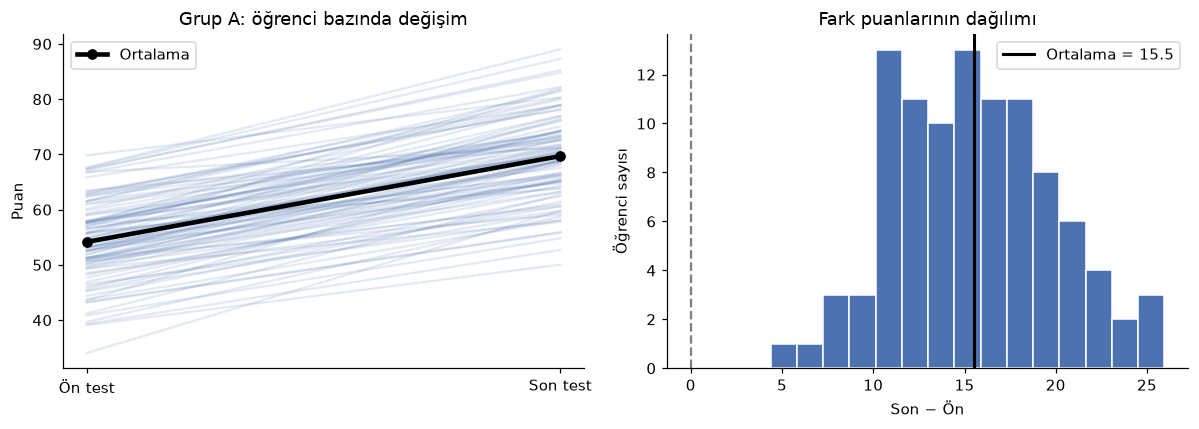

In [24]:
fig, eksenler = plt.subplots(1, 2, figsize=(11, 4))

for _, satir in df_best.iterrows():
    eksenler[0].plot([0, 1], [satir["ön"], satir["son"]], color=RENKLER[best_letter], alpha=0.15)
eksenler[0].plot([0, 1], [df_best["ön"].mean(), df_best["son"].mean()], color="black", lw=3,
                 marker="o", label="Ortalama")
eksenler[0].set_xticks([0, 1], ["Ön test", "Son test"])
eksenler[0].set_ylabel("Puan")
eksenler[0].set_title(f"Grup {best_letter}: öğrenci bazında değişim")
eksenler[0].legend()

eksenler[1].hist(fark, bins=15, color=RENKLER[best_letter], edgecolor="white")
eksenler[1].axvline(0, color="gray", ls="--")
eksenler[1].axvline(fark.mean(), color="black", lw=2, label=f"Ortalama = {fark.mean():.1f}")
eksenler[1].set_xlabel("Son − Ön")
eksenler[1].set_ylabel("Öğrenci sayısı")
eksenler[1].set_title("Fark puanlarının dağılımı")
eksenler[1].legend()

plt.tight_layout()
plt.show()

# Sonuçlar ne anlama geliyor?

Aşağıdaki rapor, yukarıdaki test sonuçlarından **otomatik** oluşturulur; veri değişirse rapor da güncellenir.

In [25]:
print("=== Ön Test Denkliği ===")
print(f"F(2, {3 * n - 3}) = {on_f:.2f}, {p_yaz(on_p)}")
print("Gruplar başlangıçta denktir." if on_denk else
      "Gruplar başlangıçta denk değildir; kazanç analizi dikkate alınmalıdır.")

print(f"\n=== {YONTEM_ADI[yontem]} Sonucu ===")
if yontem == "kruskal":
    print(f"H({sd_arasi}) = {kw.statistic:.2f}, {p_yaz(kw.pvalue)}, ε² = {eps2:.3f}")
else:
    print(f"F({sd_arasi}, {sd_ici}) = {anova.statistic:.2f}, {p_yaz(anova.pvalue)}, η² = {eta2:.3f}")
print("Gruplar arasında anlamlı bir farklılık vardır." if gruplar_farkli else
      "Gruplar arasında anlamlı bir farklılık yoktur.")

print(f"\n=== Post-hoc ({posthoc_adi}) ===")
for _, s in posthoc.iterrows():
    print(f"{s['Grup 1']} – {s['Grup 2']}: fark = {s['Ort. farkı']:+.2f}, "
          f"{p_yaz(s['p (düzeltilmiş)'])} ({'anlamlı' if s['p (düzeltilmiş)'] < ALPHA else 'anlamlı değil'})")

print("\n=== En Etkili Yöntem ===")
print(f"En etkili yöntem: Grup {best_letter}" if aday_ustun else
      f"Grup {best_letter} en yüksek ortalamaya sahip, ancak üstünlüğü tüm gruplara karşı anlamlı değil.")

print(f"\n=== {'Bağımlı t-Testi' if fark_normal else 'Wilcoxon Testi'} Sonucu (Grup {best_letter}) ===")
if fark_normal:
    print(f"t({len(fark) - 1}) = {t_sonuc.statistic:.2f}, {p_yaz(t_sonuc.pvalue)}, d_z = {dz:.2f}, "
          f"ortalama artış = {fark.mean():.2f} [%95 GA {t_ga.low:.2f}, {t_ga.high:.2f}]")
else:
    print(f"W = {w_sonuc.statistic:.1f}, {p_yaz(w_sonuc.pvalue)}, r = {r_rb:.2f}, medyan artış = {fark.median():.2f}")
print("Ön test ve son test puanları arasında anlamlı bir farklılık vardır." if bagimli_p < ALPHA else
      "Ön test ve son test puanları arasında anlamlı bir farklılık yoktur.")

=== Ön Test Denkliği ===
F(2, 297) = 0.79, p = .453
Gruplar başlangıçta denktir.

=== Tek yönlü ANOVA Sonucu ===
F(2, 297) = 30.41, p < .001, η² = 0.170
Gruplar arasında anlamlı bir farklılık vardır.

=== Post-hoc (Tukey HSD) ===
A – B: fark = +9.75, p < .001 (anlamlı)
A – C: fark = +4.76, p < .001 (anlamlı)
B – C: fark = -4.99, p < .001 (anlamlı)

=== En Etkili Yöntem ===
En etkili yöntem: Grup A

=== Bağımlı t-Testi Sonucu (Grup A) ===
t(99) = 35.14, p < .001, d_z = 3.51, ortalama artış = 15.53 [%95 GA 14.66, 16.41]
Ön test ve son test puanları arasında anlamlı bir farklılık vardır.


### Yorum

*(seed = 42 ile elde edilen sonuçlara göre)*

- **Ön test denkliği:** Grupların ön test ortalamaları arasında anlamlı fark yoktur (F(2, 297) = 0.79, p = .453). Gruplar başlangıçta denk olduğu için son test puanlarındaki farklar yöntemlere bağlanabilir.
- **Varsayımlar:** Üç grubun son test puanları normal dağılmaktadır (Shapiro-Wilk, tüm p > .05) ve varyanslar homojendir (Levene, p = .225). Bu nedenle parametrik test (tek yönlü ANOVA) kullanılmıştır.
- **Gruplar arası fark:** Yöntemler arasında son test puanları bakımından anlamlı fark vardır (F(2, 297) = 30.41, p < .001, η² = 0.17). Son test puanlarındaki varyansın yaklaşık %17'si yöntem farkıyla açıklanmaktadır; bu büyük bir etkidir.
- **Post-hoc:** Tukey HSD sonuçlarına göre üç ikili karşılaştırmanın tamamı anlamlıdır. Sıralama A (69.7) > C (64.9) > B (60.0) şeklindedir.
- **En etkili yöntem:** A yöntemi hem B'den (fark = 9.75) hem de C'den (fark = 4.76) anlamlı olarak yüksektir. Kazanç puanı analizi de aynı sonucu verir (A: +15.5, C: +9.4, B: +4.8).
- **A grubunda ön–son fark:** Fark puanları normal dağıldığı için bağımlı t-testi kullanılmıştır. Son test puanları ön teste göre anlamlı olarak yüksektir (t(99) = 35.14, p < .001). Ortalama artış 15.53 puandır (%95 GA [14.66, 16.41]) ve etki büyüklüğü çok büyüktür (d_z = 3.51).

**Sonuç:** A yöntemi incelenen yöntemler arasında en etkili yöntemdir ve uygulandığı grupta başarıyı ortalama yaklaşık 15.5 puan artırmıştır.

*Not:* Veriler simülasyonla üretildiği için etki büyüklükleri gerçek sınıf verilerine göre oldukça yüksektir.
